# How this notebook works — a guide for the paper's contributors

## Research question and central idea

**Can we predict which microscopy image patch an LLM will choose, and identify measurable visual cues that help explain those choices?** GPT is shown ten candidate patches and asked to select the one that looks most scientifically informative for the next measurement. We observe the choice, describe the candidate images numerically, and fit a model that predicts the winner.

**Image scan → ten candidate patches → observed choice → visual descriptors → learned preference model → prediction and validation.**

This is an analysis of **observed selection behavior**. “Scientifically informative” is the instruction given to GPT; the notebook does not measure downstream experimental information gain or prove that its selections are scientifically optimal.

## 1. Understand the data and the two kinds of agent

The notebook loads **scan_main_0000.ibw**, a six-channel piezoresponse force microscopy (PFM) scan, and analyzes channel index 2, identified here as **Amplitude2**. It preserves the image orientation used by the recorded coordinates and rescales the full image to 0–1. Each decision presents ten **16 × 16 pixel** patches from randomly sampled locations.

The opening **simulated-agent** example uses a reward we deliberately specify: 0.10 × brightness + 0.35 × contrast + 0.55 × edge strength, after feature normalization. Its winner is the candidate with the largest reward. This demonstrates how choices can be generated and then modeled when the preference rule is known. Recovering a useful weight ordering is a sanity check; the observed winners do not uniquely determine the original weights.

The later **GPT experiment** replaces that specified reward with actual image-based choices. GPT receives labeled, 8-bit grayscale PNG patches and returns a candidate index from 0 to 9. The analysis therefore asks what visual rule predicts GPT's decisions; it does not assume GPT follows the simulated reward. Although decisions are indexed in sequence, the fitted model uses the current candidate set, without a learned state or history-dependent policy.

The saved analysis contains **40 training decisions and 12 additional test decisions**. Each training decision has ten candidate rows and exactly one selected row: **400 rows represent 40 choices**, not 400 independent decisions.

## 2. Keep the source of the choices explicit

The notebook can read cached GPT choices, collect new choices through the API, or use separately labeled stand-in data when GPT data are unavailable. Check **DATA_SOURCE**, **SOURCE_KIND**, **UNSEEN_SOURCE**, and the final computed report before quoting a result. The optional opening demo can show an illustrative stand-in even when the later analysis uses GPT data.

Coordinate and selection checks verify dataset structure. API metadata adds provenance such as the prompt, requested and returned model, response identifiers, raw replies, and image checksum. A supplied CSV without this metadata does not by itself establish who made its choices. Training and test results must use the same declared choice source.

## 3. Translate visual hypotheses into measurable features

The starter explores two-dimensional principal component analysis (PCA) and simple intensity statistics. The **“My solution”** section then builds **16 interpretable features**, using the same 8-bit pixel values sent to GPT:

| Feature group | What it measures |
|---|---|
| Brightness | Mean intensity |
| Contrast | Intensity variation, percentile range, and entropy |
| Edges | Gradient strength, strong gradients, Canny edge density, and Laplacian response |
| Thin dark lines | Morphological and ridge-filter responses; called “Domain walls” in the code |
| Geometry | Mixed gradient orientations, corner/junction-like response, and intensity bimodality |
| Regular stripes | Concentration of Fourier power in a dominant peak |
| Novelty | Average pixel distance from the other nine candidates |

These are **image descriptors**. A dark ridge or mixed orientation can motivate a physical hypothesis, but amplitude alone cannot confirm a domain wall, polarization direction, or a junction's physical identity.

For each feature, the model uses a **z-score within the current set of ten candidates**:

$$
z_{sik}=\frac{f_{sik}-\bar f_{sk}}{\sigma_{sk}+\epsilon}.
$$

Here, \(s\) is the decision, \(i\) the candidate, and \(k\) the feature. This expresses each patch relative to its alternatives. For example, a high edge score means stronger edges than other patches in that set. These calculations use candidate images, not their selection labels.

## 4. Fit a model for “choose one of ten”

A conditional-logit model assigns each candidate a utility and converts the ten utilities into choice probabilities:

$$
u_{si}=w^\top z_{si},
\qquad
P(i\mid s)=\frac{\exp(u_{si})}{\sum_{j=0}^{9}\exp(u_{sj})}.
$$

Training minimizes the negative log probability of each observed winner, with an L2 penalty to discourage large coefficients:

$$
\mathcal L(w)=-\sum_s\log P(c_s\mid s)+\lambda\lVert w\rVert_2^2,
\qquad \lambda=1.0
$$

for the main comparisons. The predicted winner is the candidate with the greatest utility.

This directly models competition within a decision. A positive coefficient associates a larger relative feature value with higher predicted preference, conditional on the other descriptors. A shared intercept would cancel in the softmax. Correlated features and regularization affect the coefficients, so the learned utility is a **predictive surrogate for preference**, not a uniquely recovered internal GPT reward.

## 5. Test prediction and investigate which cues help

The main comparison uses **leave-one-decision-out validation**: train on 39 complete decisions, predict all ten candidates in the remaining decision, and repeat for all 40. Holding out entire decisions respects the task's grouping. PCA fitting and single-feature selection occur within the training folds. This table is separate from the starter's earlier 75/25 split.

Compare the choice model with random selection, PCA plus linear regression, statistical features plus linear regression, a three-feature choice model, a single-feature baseline, and a random forest. Report exact-winner accuracy, top-three accuracy, and the observed winner's rank. Random selection gives 10% exact-winner accuracy and 30% top-three accuracy.

To assess feature groups, remove one group, refit the model, and compare held-out log likelihood. A positive loss on removal means the group contributes predictive information beyond the remaining features. It does not prove GPT causally used that cue. Finally, fit on all 40 decisions, freeze the weights, and score the 12 additional candidate sets.

## 6. What the saved results support

The saved final output labels its source as **GPT API cache with response metadata recorded**:

| Evaluation of the 16-feature choice model | Exact winner | Top three |
|---|---:|---:|
| Leave-one-decision-out, 40 decisions | 13/40 (32.5%) | 31/40 (77.5%) |
| Additional sets, frozen model | 8/12 (66.7%) | 12/12 (100%) |

These are saved results, not a new run performed for this explanation. In the saved ablation, **Edges** provides the largest incremental predictive gain, followed by the thin-dark-line group. The data are small, the feature design was informed by this image and earlier stand-in analysis, and additional patches can overlap training patches on the **same scan**. The results support an exploratory account of predictable visual preferences; they do not establish generalization to other scans or materials. Optional GPT explanations are further hypotheses, not direct evidence of the mechanism behind a choice.

## 7. Use this structure when writing the paper together

- **Introduction:** motivate the problem of auditing an autonomous agent's measurement selections and state the behavioral research question.
- **Data and collection:** describe the scan/channel, preprocessing, patch sampling, prompt, model provenance, and distinction between simulated, stand-in, and GPT choices.
- **Methods:** define the 16 descriptors, within-set scaling, conditional-logit objective, baselines, and decision-level evaluation.
- **Results:** use the final computed comparison, feature ablations, prediction galleries, and additional-set scores; identify the data source and denominators.
- **Discussion and reproducibility:** explain the small sample, spatial overlap, adaptive feature design, limits of physical interpretation, and need for validation on independent scans.

Contributors should link each claim to the relevant code, saved output, or provenance record and document their actual contributions separately. A rerun requires the companion support module, scan, caches, and dependencies; this introduction does not execute code or make API calls.

---

*The original notebook introduction and all existing analysis follow below.*


# <font color = "red">**Hackathon Challenge — Deciphering the Decision Logic of an AI Agent**</font>

- Can we infer what an AI agent values by observing the sequence of decisions it makes?

- In this challenge, GPT acts as an autonomous microscopy agent that repeatedly selects one measurement location from a set of candidate AFM image patches.

- We record its decisions and then attempt to reverse-engineer the hidden logic behind those choices using visual, statistical, and data-driven methods.

<font color = "blue" size = 6>**Goal**</font>: develop a method that best explains GPT’s behavior and predicts its future decisions on unseen candidate sets.

---
*Solved by Surya — my work starts at **“My solution”** near the end; small marked edits in the GPT cells let the notebook run with or without an API key.*

**Verified analysis copy.** The saved results now use 40 GPT API decisions and 12 GPT API test
decisions, with response metadata. The original notebook and stand-in CSVs are preserved for
reference. Always check the source printed by the collection cell and final report.

Run all cells from this folder. Dependencies: `numpy pandas matplotlib scipy scikit-learn scikit-image
igor2 nbformat nbclient ipykernel openai`. Set `OPENAI_API_KEY` in your local environment to collect real
choices; no key belongs in notebook source. The API collection saves each completed decision and can
resume. API demo and reason calls are separately opt-in.


**Key setup:** Run all cells interactively. The GPT client setup cell now asks for your new API key using a hidden input if no environment key exists. Entering a blank value uses stand-in data. The offline verification script deliberately disables API collection.


<a href="https://colab.research.google.com/github/kbarakati/camm_hackathon/blob/k4my4r/docs/day_20_10092026/llm_decision_making.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Imports and reproducibility

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from igor2 import binarywave
from types import SimpleNamespace
from pathlib import Path

# Machine-learning tools we will use later
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)

## load data

In [ ]:
fname = Path("scan_main_0000.ibw")
wave = binarywave.load(str(fname))["wave"]
# aespm.tools.IBWData uses wave['wData'].T, transposing BOTH spatial axes.
# Keep this exact orientation and dtype to preserve all recorded patch coordinates.
channel_data = wave["wData"].T
channels = [x.decode("utf-8", errors="replace") for x in wave["labels"][2] if x]
data = SimpleNamespace(data=channel_data, channels=channels, mode="PFM (DART, six channels)")
print("Channels:", data.channels)
print("Shape:", data.data.shape)
print("Mode:", data.mode)

Channels: ['HeightRetrace', 'Amplitude1Retrace', 'Amplitude2Retrace', 'Phase1Retracece', 'Phase2Retraceace', 'FrequencyRetrace']
Shape: (6, 256, 256)
Mode: PFM (DART, six channels)


plot the AFM image

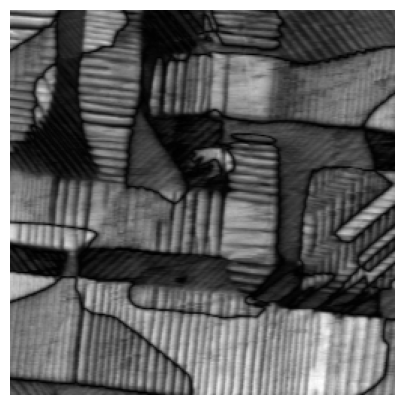

In [ ]:
channel_index = 2

img = data.data[channel_index]

assert np.isfinite(img).all() and np.ptp(img) > 0
img = (img - img.min()) / (img.max() - img.min())

plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

## Generate measurement locations

At each experimental step, the **agent** should not search the entire image pixel-by-pixel. Instead, we give it 10 possible locations and ask:

Which of these 10 regions should I measure next?

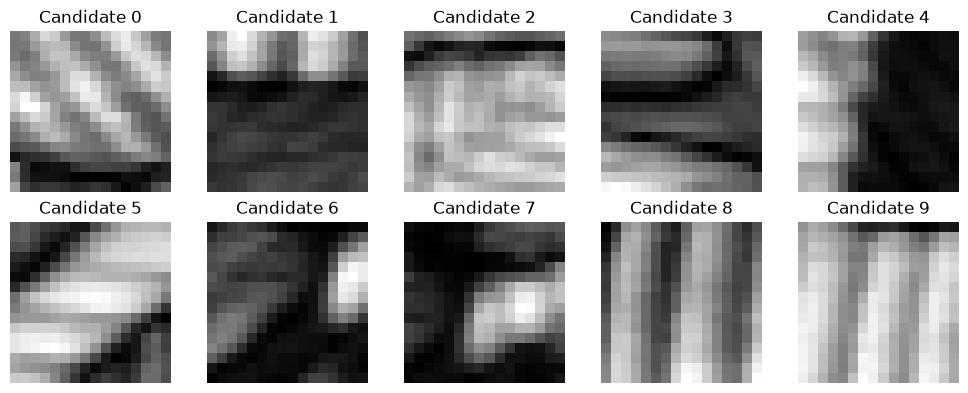

In [ ]:
N_CANDIDATES = 10
PATCH_SIZE = 16

rng = np.random.default_rng(42)

H, W = img.shape
half = PATCH_SIZE // 2

# Random patch centers
candidate_centers = [
    (
        rng.integers(half, H - half),
        rng.integers(half, W - half)
    )
    for _ in range(N_CANDIDATES)
]

# Extract patches
candidate_patches = [
    img[y-half:y+half, x-half:x+half]
    for y, x in candidate_centers
]

# Display
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, (ax, patch) in enumerate(zip(axes.flat, candidate_patches)):
    ax.imshow(patch, cmap="gray")
    ax.set_title(f"Candidate {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Extract simple interpretable features

In [ ]:
# ============================================================
# BLOCK 3 — EXTRACT AND NORMALIZE PATCH FEATURES
# ============================================================

features = []

for patch in candidate_patches:

    mean_intensity = np.mean(patch)
    contrast = np.std(patch)

    gy, gx = np.gradient(patch.astype(float))
    edge_strength = np.mean(np.sqrt(gx**2 + gy**2))

    features.append([mean_intensity, contrast, edge_strength])


features = pd.DataFrame(
    features,
    columns=["mean_intensity", "contrast", "edge_strength"]
)

# # Normalize every feature between 0 and 1
features = (features - features.min()) / (features.max() - features.min())

features.round(3)

,mean_intensity,contrast,edge_strength
0,0.155,0.000,0.069
1,0.192,0.331,0.186
2,0.406,0.141,0.296
3,0.302,0.416,0.514
4,0.354,1.000,0.286
5,0.767,0.975,1.000
6,0.000,0.047,0.000
7,0.065,0.317,0.189
8,0.741,0.257,0.728
9,1.000,0.437,0.811


## agent’s hidden scientific objective

In [ ]:
# ============================================================
# BLOCK 5 — HIDDEN REWARD FUNCTION
# ============================================================

weights = {
    "mean_intensity": 0.10,
    "contrast":       0.35,
    "edge_strength":  0.55
}

reward = (
    weights["mean_intensity"] * features["mean_intensity"] +
    weights["contrast"]       * features["contrast"] +
    weights["edge_strength"]  * features["edge_strength"]
)

reward

0    0.053316
1    0.237190
2    0.252768
3    0.458798
4    0.542839
5    0.967814
6    0.016566
7    0.221005
8    0.564713
9    0.699297
dtype: float64

## Let the agent choose one candidate

In [ ]:
selected_idx = reward.idxmax()

print(f"Agent selected Candidate {selected_idx}")
print(f"Reward = {reward[selected_idx]:.3f}")

Agent selected Candidate 5
Reward = 0.968


which patch

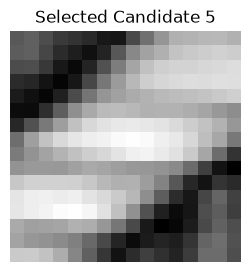

In [ ]:
plt.figure(figsize=(3, 3))

plt.imshow(candidate_patches[selected_idx], cmap="gray")
plt.title(f"Selected Candidate {selected_idx}")
plt.axis("off")

plt.show()

What happened here?
The agent evaluated all 10 candidates using its hidden objective:

features --> reward --> selection

## Generate a full decision history

In [ ]:
N_STEPS = 30
history = []

for step in range(N_STEPS):

    # Generate 10 new candidate locations
    centers = [
        (
            rng.integers(half, H - half),
            rng.integers(half, W - half)
        )
        for _ in range(N_CANDIDATES)
    ]

    # Extract patches
    patches = [
        img[y-half:y+half, x-half:x+half]
        for y, x in centers
    ]

    # Compute features
    step_features = []

    for patch in patches:
        mean_intensity = np.mean(patch)
        contrast = np.std(patch)

        gy, gx = np.gradient(patch)
        edge_strength = np.mean(np.sqrt(gx**2 + gy**2))

        step_features.append([
            mean_intensity,
            contrast,
            edge_strength
        ])

    step_features = pd.DataFrame(
        step_features,
        columns=["mean_intensity", "contrast", "edge_strength"]
    )

    # Normalize features within this decision step
    fmin = step_features.min()
    fmax = step_features.max()

    step_features = (step_features - fmin) / (fmax - fmin + 1e-12)

    # Hidden reward
    step_reward = (
        weights["mean_intensity"] * step_features["mean_intensity"] +
        weights["contrast"]       * step_features["contrast"] +
        weights["edge_strength"]  * step_features["edge_strength"]
    )

    # Agent chooses highest-reward candidate
    selected = step_reward.idxmax()

    # Save all 10 candidates
    for i, (y, x) in enumerate(centers):

        history.append({
            "step": step,
            "candidate": i,
            "x": x,
            "y": y,
            "mean_intensity": step_features.loc[i, "mean_intensity"],
            "contrast": step_features.loc[i, "contrast"],
            "edge_strength": step_features.loc[i, "edge_strength"],
            "reward_true": step_reward[i],
            "selected": int(i == selected)
        })


history = pd.DataFrame(history)

history.head(20)

,step,candidate,x,y,mean_intensity,contrast,edge_strength,reward_true,selected
0,0,0,96,128,0.311457,0.410222,0.369807,0.378117,0
1,0,1,230,51,0.506030,0.000000,0.000000,0.050603,0
2,0,2,162,195,0.000000,0.867689,0.791659,0.739103,0
3,0,3,205,104,0.055246,0.341110,0.304016,0.292122,0
4,0,4,114,138,0.285009,0.629881,1.000000,0.798959,0
5,0,5,62,116,0.273547,0.658976,0.539947,0.554968,0
6,0,6,141,30,0.280501,1.000000,0.811307,0.824269,1
7,0,7,23,221,0.575267,0.016500,0.068034,0.100721,0
8,0,8,206,213,1.000000,0.486381,0.601409,0.601009,0
9,0,9,159,74,0.178435,0.901804,0.464713,0.589067,0


## History of decision on the map

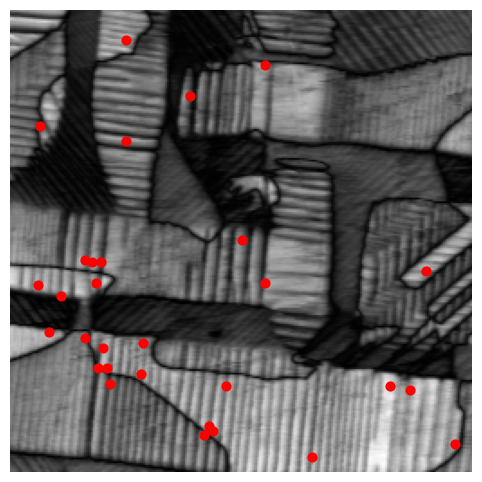

In [ ]:
selected_history = history[history["selected"] == 1]

plt.figure(figsize=(6, 6))

plt.imshow(img, cmap="gray")

plt.scatter(
    selected_history["x"],
    selected_history["y"],
    s=40,
    facecolors="r",
    edgecolors="r",

    marker = "o"
)

plt.axis("off")
plt.show()

first 4 decison been among these options

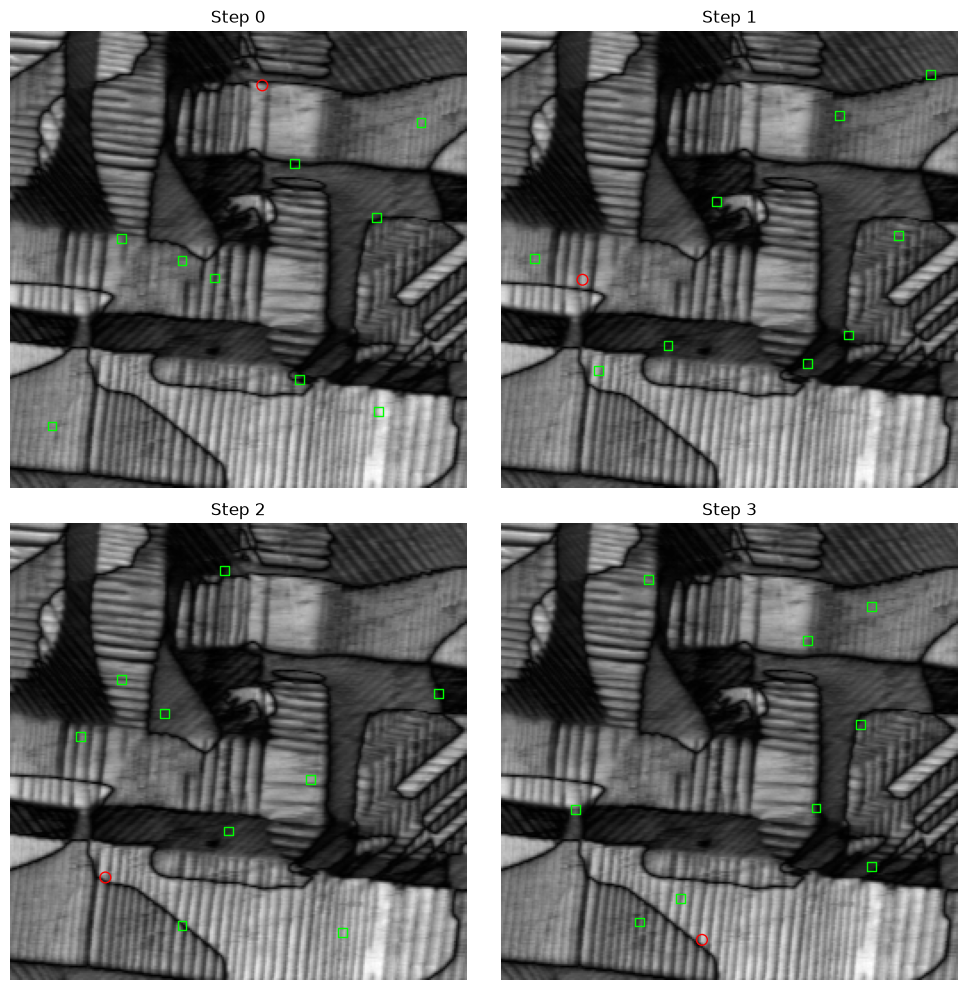

In [ ]:
# ============================================================
# PLOT FIRST 4 DECISION STEPS (2x2 GRID)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for ax, step in zip(axes.flat, range(4)):

    step_data = history[history["step"] == step]
    selected = step_data[step_data["selected"] == 1]
    not_selected = step_data[step_data["selected"] == 0]

    ax.imshow(img, cmap="gray")

    # 9 not selected
    ax.scatter(
        not_selected["x"],
        not_selected["y"],
        s=40,
        marker="s",
        facecolors="none",
        edgecolors="lime"
    )

    # 1 selected
    ax.scatter(
        selected["x"],
        selected["y"],
        s=60,
        marker="o",
        facecolors="none",
        edgecolors="red"
    )

    ax.set_title(f"Step {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## decipher the hidden reward

Compare what the agent selects vs rejects

In [ ]:
feature_cols = [
    "mean_intensity",
    "contrast",
    "edge_strength"
]

comparison = history.groupby("selected")[feature_cols].mean()

comparison.index = ["Not selected", "Selected"]

comparison.round(3)

,mean_intensity,contrast,edge_strength
Not selected,0.464,0.433,0.428
Selected,0.674,0.930,0.975


fit a model that tries to predict the agent's choices from the features

In [ ]:
X = history[feature_cols]
y = history["selected"]

model = LogisticRegression()
model.fit(X, y)

learned_weights = pd.Series(
    model.coef_[0],
    index=feature_cols
)

learned_weights

mean_intensity    1.115380
contrast          3.224696
edge_strength     3.400392
dtype: float32

In [ ]:
importance = np.abs(learned_weights)

importance = importance / importance.sum()

importance = importance.sort_values(ascending=False)

importance.round(3)

edge_strength     0.439
contrast          0.417
mean_intensity    0.144
dtype: float32

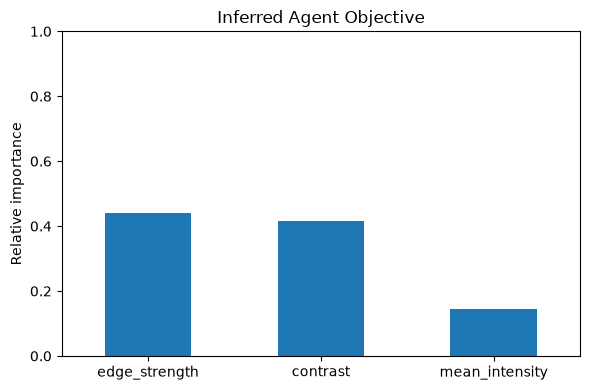

In [ ]:
plt.figure(figsize=(6, 4))

importance.plot(kind="bar")

plt.ylabel("Relative importance")
plt.title("Inferred Agent Objective")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

Compare inferred weights with the true hidden reward

In [ ]:
true_weights = pd.Series(weights)

comparison_weights = pd.DataFrame({
    "True": true_weights,
    "Inferred": importance
})

comparison_weights

,True,Inferred
contrast,0.35,0.416602
edge_strength,0.55,0.439301
mean_intensity,0.10,0.144097


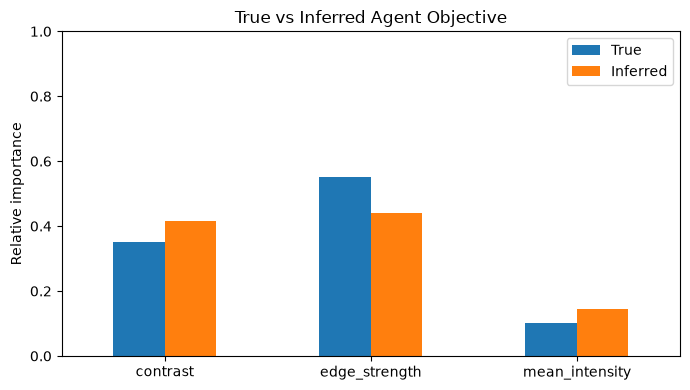

In [ ]:
comparison_weights.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.ylabel("Relative importance")
plt.title("True vs Inferred Agent Objective")
plt.xticks(rotation=0)
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

# Real LLM decision making

Previously, we defined the reward and the simulated agent followed it.

Now, GPT will make the decisions itself, and we will observe its choices and try to infer what implicit criteria explain them.

In [ ]:
# Optional in Jupyter: %pip install openai
# See requirements_day20.txt for the full environment.

In [ ]:
import os
from getpass import getpass
from day20_support import (PROMPT, parse_choice, validate_history, read_cache,
                          collect_history, wilson_interval)
MODEL = "gpt-5.6-sol"
if not os.environ.get("OPENAI_API_KEY", "").strip() and os.environ.get("DAY20_OFFLINE") != "1":
    entered_key = getpass("Enter your NEW OpenAI API key (hidden; blank uses stand-in data): ").strip()
    if entered_key:
        os.environ["OPENAI_API_KEY"] = entered_key
    del entered_key
USE_GPT = bool(os.environ.get("OPENAI_API_KEY", "").strip())
RUN_DEMO_API_CALLS = False
RUN_REASON_API_CALLS = False
if USE_GPT:
    from openai import OpenAI
    client = OpenAI()  # SDK reads OPENAI_API_KEY from the environment.
    print("GPT client configured; collection will use existing cache or request decisions.")
else:
    print("No API key: load a supplied GPT cache if present, otherwise use STAND-IN data.")

No API key: load a supplied GPT cache if present, otherwise use STAND-IN data.


## Convert candidate patches to PNG/base64

In [ ]:
import io
import base64
from PIL import Image

def patch_to_base64(patch):

    # Convert normalized 0–1 image to 8-bit grayscale
    patch_uint8 = (patch * 255).clip(0, 255).astype(np.uint8)

    image = Image.fromarray(patch_uint8)

    buffer = io.BytesIO()
    image.save(buffer, format="PNG")

    encoded = base64.b64encode(buffer.getvalue()).decode("utf-8")

    return f"data:image/png;base64,{encoded}"


candidate_images = [
    patch_to_base64(patch)
    for patch in candidate_patches
]

print(f"Prepared {len(candidate_images)} candidate images for GPT.")

Prepared 10 candidate images for GPT.


## Ask GPT to make one real decision

define prompt

In [ ]:
content = [
    {
        "type": "input_text",
        "text": """
You are controlling an autonomous microscopy experiment.

You are given 10 candidate image patches from possible measurement locations.

Select the ONE candidate that you believe would be the most scientifically
informative location to measure next.

Base your decision only on the visual information in the patches.

Return ONLY the candidate number from 0 to 9.
"""
    }
]

for i, image in enumerate(candidate_images):

    content.append({
        "type": "input_text",
        "text": f"Candidate {i}"
    })

    content.append({
        "type": "input_image",
        "image_url": image,
        "detail": "high"
    })

## make the actual API call

In [ ]:
if USE_GPT and RUN_DEMO_API_CALLS:
    response = client.responses.create(model=MODEL, input=[{"role": "user", "content": content}])
    gpt_choice = parse_choice(response.output_text)
    print(f"GPT selected Candidate {gpt_choice}")
else:
    gpt_choice = 3
    print("Illustrative stand-in demo: Candidate 3 (not an API result).")

Illustrative stand-in demo: Candidate 3 (not an API result).


visualize the decision

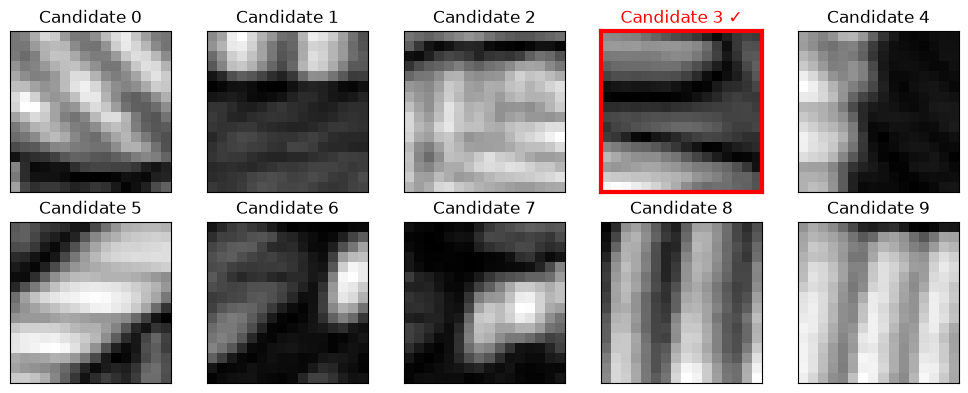

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, (ax, patch) in enumerate(zip(axes.flat, candidate_patches)):

    ax.imshow(patch, cmap="gray")

    if i == gpt_choice:
        ax.set_title(f"Candidate {i} ✓", color="red")
        for spine in ax.spines.values():
            spine.set_edgecolor("red")
            spine.set_linewidth(3)
    else:
        ax.set_title(f"Candidate {i}")

    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

test gpt decision on same set to check if it is not random

In [ ]:
from collections import Counter

N_REPEATS = 3
choices = []

if USE_GPT and RUN_DEMO_API_CALLS:
    for i in range(N_REPEATS):
        response = client.responses.create(
            model=MODEL,
            input=[{"role": "user", "content": content}],
            extra_headers={"Accept-Encoding": "identity"}
        )
        choice = parse_choice(response.output_text)
        choices.append(choice)
        print(f"Run {i+1:02d} → Candidate {choice}")
else:
    print("Repeat-consistency API demo is disabled.")

Repeat-consistency API demo is disabled.


In [ ]:
if choices:
    counts = Counter(choices)
    most_common_choice, n_common = counts.most_common(1)[0]
    consistency = n_common / N_REPEATS
    print(f"\nMost selected candidate: {most_common_choice}")
    print(f"Consistency: {consistency:.1%}")

## Build a GPT decision history

In [ ]:
def get_candidates(img, rng):
    h, w = img.shape
    centers = [(rng.integers(half, h-half), rng.integers(half, w-half))
               for _ in range(N_CANDIDATES)]
    return centers, [img[y-half:y+half, x-half:x+half] for y, x in centers]

def ask_gpt_record(patches):
    content = [{"type": "input_text", "text": PROMPT}]
    for i, patch in enumerate(patches):
        content += [{"type": "input_text", "text": f"Candidate {i}"},
                    {"type": "input_image", "image_url": patch_to_base64(patch), "detail": "high"}]
    response = client.responses.create(model=MODEL, input=[{"role": "user", "content": content}])
    choice = parse_choice(response.output_text)
    return choice, {"response_id": response.id, "returned_model": response.model,
                    "output_text": response.output_text}

def ask_gpt(patches):
    return ask_gpt_record(patches)[0]

In [ ]:
N_GPT_STEPS = 40
if Path("gpt_history.csv").exists():
    gpt_history, DATA_SOURCE = read_cache("gpt_history.csv", img, MODEL, 123, N_GPT_STEPS)
    SOURCE_KIND = "GPT"
elif USE_GPT:
    gpt_history, DATA_SOURCE = collect_history("gpt_history.csv", img, MODEL, 123,
        N_GPT_STEPS, get_candidates, ask_gpt_record)
    SOURCE_KIND = "GPT"
else:
    gpt_history = validate_history(pd.read_csv("gpt_history_standin.csv"),
                                  img.shape, 123, N_GPT_STEPS)
    SOURCE_KIND = "STAND-IN"
    DATA_SOURCE = "STAND-IN (supplied choices; origin not independently verified)"
print(f"Decision history source: {DATA_SOURCE} | {gpt_history.step.nunique()} decisions")

Decision history source: GPT API cache (response metadata recorded) | 40 decisions


**Data provenance.** The supplied CSVs contain coordinates, candidate IDs, and selected flags. Their
candidate coordinates are checked against seed 123 (training) or 2026 (new sets), with exactly ten
candidates and one valid selection per decision. These checks verify dataset structure, not the
identity of the chooser. The original notebook describes Claude as the stand-in. Real API collection
records the requested model, prompt, image checksum, response IDs, returned model, and raw replies.
An externally supplied GPT CSV without metadata is explicitly labelled as unverified in origin.

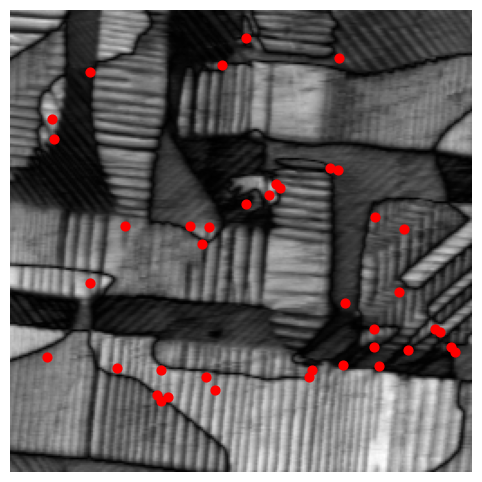

In [ ]:
selected_gpt = gpt_history[gpt_history["selected"] == 1]

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")

plt.scatter(
    selected_gpt["x"],
    selected_gpt["y"],
    s=40,
    marker="o",
    facecolors="red",
    edgecolors="red"
)

plt.axis("off")
plt.show()

## Reconstruct the decision episodes

In [ ]:
# ============================================================
# REVERSE ENGINEERING — BLOCK 1: RECONSTRUCT DECISION EPISODES
# ============================================================

decision_history = []

for step in sorted(gpt_history["step"].unique()):

    step_data = gpt_history[gpt_history["step"] == step]

    patches = [
        img[
            int(row.y)-half:int(row.y)+half,
            int(row.x)-half:int(row.x)+half
        ]
        for _, row in step_data.iterrows()
    ]

    selected = int(
        step_data.loc[step_data["selected"] == 1, "candidate"].iloc[0]
    )

    decision_history.append({
        "step": step,
        "patches": patches,
        "selected": selected
    })

print(f"Reconstructed {len(decision_history)} decisions ({DATA_SOURCE}).")

Reconstructed 40 decisions (GPT API cache (response metadata recorded)).


## Build the patch dataset

In [ ]:
X_patches = []
y_selected = []
step_ids = []
candidate_ids = []

for _, row in gpt_history.iterrows():

    x = int(row["x"])
    y = int(row["y"])

    patch = img[
        y-half:y+half,
        x-half:x+half
    ]

    X_patches.append(patch)
    y_selected.append(row["selected"])
    step_ids.append(row["step"])
    candidate_ids.append(row["candidate"])


X_patches = np.array(X_patches)
y_selected = np.array(y_selected)

print("Patch dataset:", X_patches.shape)
print("Selected:", y_selected.sum())
print("Not selected:", len(y_selected) - y_selected.sum())

Patch dataset: (400, 16, 16)
Selected: 40
Not selected: 360


## Approach 1 — Visual Deciphering

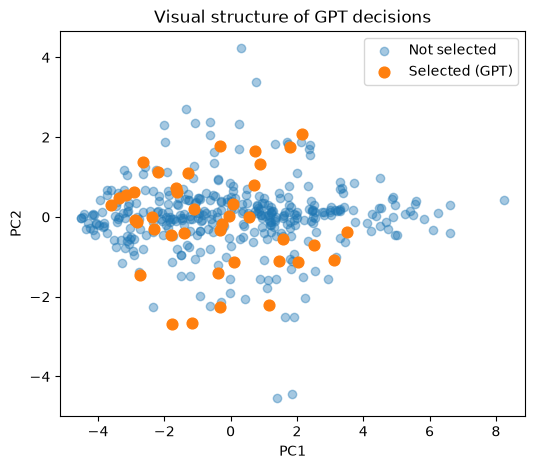

In [ ]:
from sklearn.decomposition import PCA

# Flatten image patches
X = X_patches.reshape(len(X_patches), -1)

# Reduce to 2 dimensions
X_pca = PCA(n_components=2).fit_transform(X)

# Plot
plt.figure(figsize=(6, 5))

plt.scatter(
    X_pca[y_selected == 0, 0],
    X_pca[y_selected == 0, 1],
    alpha=0.4,
    label="Not selected"
)

plt.scatter(
    X_pca[y_selected == 1, 0],
    X_pca[y_selected == 1, 1],
    s=60,
    label=f"Selected ({SOURCE_KIND})"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Visual structure of {SOURCE_KIND} decisions")
plt.legend()
plt.show()

**Question**

Do GPT-selected patches occupy a distinct region of image space?

- If yes, GPT may have a consistent visual preference.

- If not, the decision rule may be more complex than the first two PCA dimensions can reveal.

In [ ]:
# ============================================================
# TRAIN / TEST SPLIT BY DECISION STEP
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

step_ids = np.array(step_ids)

train_steps, test_steps = train_test_split(
    np.unique(step_ids),
    test_size=0.25,
    random_state=42
)

train_mask = np.isin(step_ids, train_steps)
test_mask  = np.isin(step_ids, test_steps)


def decision_accuracy(scores, labels, steps):

    correct = []

    for step in np.unique(steps):

        mask = steps == step

        predicted = np.argmax(scores[mask])
        actual    = np.argmax(labels[mask])

        correct.append(predicted == actual)

    return np.mean(correct)

Can PCA predict GPT's decision?

In [ ]:
pca = PCA(n_components=2)

X_train = pca.fit_transform(X[train_mask])
X_test  = pca.transform(X[test_mask])

model = LinearRegression()
model.fit(X_train, y_selected[train_mask])

scores = model.predict(X_test)

accuracy = decision_accuracy(
    scores,
    y_selected[test_mask],
    step_ids[test_mask]
)

print(f"PCA accuracy:    {accuracy:.1%}")
print(f"Random baseline: {1/N_CANDIDATES:.1%}")

PCA accuracy:    20.0%
Random baseline: 10.0%


## Approach 2 — Statistical Deciphering

In [ ]:
from scipy.stats import skew, kurtosis, mannwhitneyu

stats = []

for patch in X_patches:

    p = patch.ravel()

    stats.append({
        "mean": np.mean(p),
        "std": np.std(p),
        "range": np.ptp(p),
        "skewness": skew(p),
        "kurtosis": kurtosis(p)
    })

stats_df = pd.DataFrame(stats)
stats_df["selected"] = y_selected

In [ ]:
results = []

for feature in stats_df.columns[:-1]:

    selected = stats_df[stats_df["selected"] == 1][feature]
    rejected = stats_df[stats_df["selected"] == 0][feature]

    U, p = mannwhitneyu(selected, rejected)

    effect = 2 * U / (len(selected) * len(rejected)) - 1

    results.append([
        feature,
        effect
    ])

results = pd.DataFrame(
    results,
    columns=["feature", "effect_size"]
)

results = results.sort_values(
    "effect_size",
    key=np.abs,
    ascending=False
)

results

,feature,effect_size
2,range,0.371250
1,std,0.328056
0,mean,-0.131806
3,skewness,0.083194
4,kurtosis,-0.064167


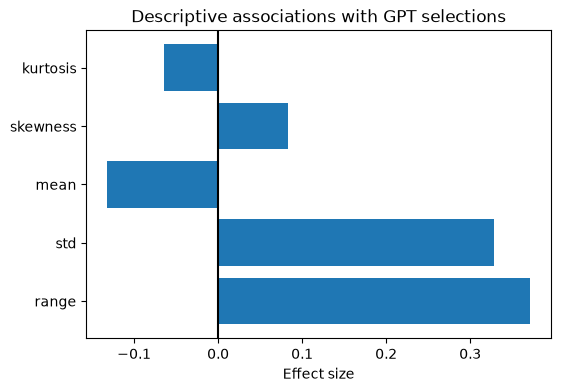

In [ ]:
plt.figure(figsize=(6, 4))

plt.barh(
    results["feature"],
    results["effect_size"]
)

plt.axvline(0, color="black")
plt.xlabel("Effect size")
plt.title(f"Descriptive associations with {SOURCE_KIND} selections")

plt.show()

Can the statistics predict GPT's decision?

In [ ]:
X_stats = stats_df.drop(columns="selected").values

model = LinearRegression()

model.fit(
    X_stats[train_mask],
    y_selected[train_mask]
)

scores = model.predict(
    X_stats[test_mask]
)

accuracy = decision_accuracy(
    scores,
    y_selected[test_mask],
    step_ids[test_mask]
)

print(f"Statistics accuracy: {accuracy:.1%}")
print(f"Random baseline:     {1/N_CANDIDATES:.1%}")

Statistics accuracy: 10.0%
Random baseline:     10.0%


# Can you develop a better way to decipher GPT and achieve higher prediction accuracy?

In [ ]:
# ============================================================
# CHALLENGE — DECIPHER GPT'S DECISION LOGIC
# ============================================================

# Can you find a representation of the image patches
# that better explains GPT's decisions?
#
# Your goal:
#
# 1. Develop your own representation / features
# 2. Train a model using the training decisions
# 3. Predict GPT's choices on the test decisions
# 4. Compare your accuracy against:
#
#       Random baseline
#       PCA approach
#       Statistical approach


# ============================================================
# YOUR CODE STARTS HERE
# ============================================================
# -> my solution is in the cells below

# ============================================================
# YOUR CODE ENDS HERE
# ============================================================

# My solution — explaining and predicting the agent's choices

## Why I changed the representation and fitting method

The agent compares ten patches and selects one. The starter predicts selected/not-selected scores
for individual patches and ranks those scores within each set. My conditional-logit model instead
fits the probability of the winner directly against the other nine candidates.

I use 16 features describing brightness, contrast, edges, thin dark ridges, orientation mixture,
junction-like structure, periodicity, and difference from the other patches. Each feature is
standardized within its own candidate set, matching the relative comparison the agent sees.

The scan is the Amplitude2 channel of a six-channel PFM dataset. Dark-line and junction detectors
are image descriptors: amplitude alone cannot establish polarization direction or confirm every
dark line as a physical domain wall.

All methods use leave-one-decision-out cross-validation: train on 39 decisions and predict the
remaining decision, repeated 40 times. I then fit on all 40 and evaluate 12 new candidate sets.
The new sets come from the same scan and may overlap earlier patches. Feature design was informed
by this image and the earlier stand-in analysis; this remains an exploratory study.

The initial illustrative demo uses a stand-in choice. The actual collection and analysis source is
printed under **Build a GPT decision history** and in the final computed report.

## Step 0 — Just look at what the agent picked

Before computing anything, I simply put each candidate set in a row and boxed the chosen patch. It's the most
"human" thing to do, and it gives me a hypothesis to test.

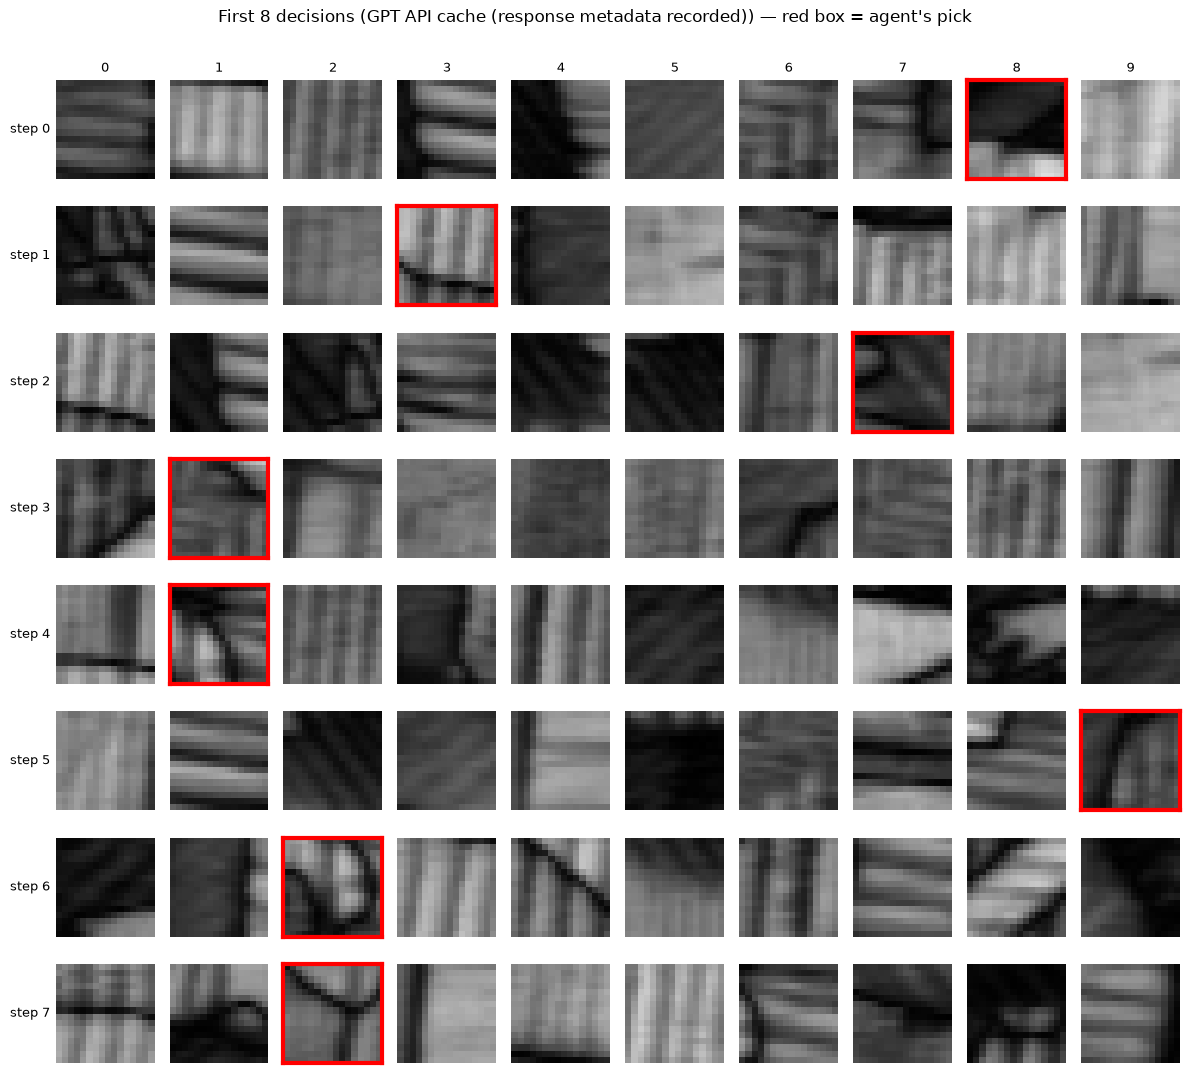

In [ ]:
def get_patch(row):
    x, y = int(row["x"]), int(row["y"])
    return img[y-half:y+half, x-half:x+half]

def show_decisions(history, steps, extra=None, title=""):
    """One row per decision; red box = agent's pick, blue dashed box = (optional) model's pick."""
    fig, axes = plt.subplots(len(steps), 10, figsize=(12, 1.35*len(steps)))
    axes = np.atleast_2d(axes)
    for r, s in enumerate(steps):
        sd = history[history["step"] == s].sort_values("candidate")
        for c, (_, row) in enumerate(sd.iterrows()):
            ax = axes[r, c]
            ax.imshow((get_patch(row)*255).astype(np.uint8), cmap="gray", vmin=0, vmax=255)
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_visible(False)
            if row["selected"] == 1:
                for sp in ax.spines.values(): sp.set_visible(True); sp.set_edgecolor("red"); sp.set_linewidth(3)
            if extra is not None and extra.get(s) == c:
                ax.add_patch(plt.Rectangle((0.5, 0.5), 14, 14, fill=False, ec="deepskyblue", lw=2, ls="--"))
            if r == 0: ax.set_title(f"{c}", fontsize=9)
        axes[r, 0].set_ylabel(f"step {s}", rotation=0, ha="right", va="center", fontsize=9)
    fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

show_decisions(gpt_history, range(8), title=f"First 8 decisions ({DATA_SOURCE}) — red box = agent's pick")

**Visual hypothesis, not a conclusion:** compare the selected patches with the other nine in
each row. Are selections associated with sharp edges, dark lines, contrast, or changing orientation?
The gallery motivates image features. The fitted model and held-out ablations test which feature
groups help predict actual choices; the earlier stand-in interpretation need not transfer to GPT.

## Step 1 — Features a microscopist would use

I compute every feature on **exactly the 8-bit image the LLM receives**, because that's all it sees. I grouped the features by the
question each one answers:

| Group | Features | Plain-language meaning |
|---|---|---|
| Brightness | `mean` | How bright (high piezo-response) is the patch? |
| Contrast | `contrast`, `range`, `entropy` | How much is going on in the gray levels? |
| Edges | `edge_strength`, `edge_max`, `canny_density`, `laplacian` | How many sharp transitions are there? |
| Domain walls | `wall_tophat`, `wall_ridge`, `wall_fraction` | Are there **thin dark lines**? (black top-hat and Sato ridge filter) |
| Geometry | `orient_mix`, `junction`, `bimodality` | Do structures run in **several directions** (junction/bend)? Does the patch split into two domains? |
| Stripes | `periodicity` | Is it a **regular, repetitive** stripe pattern? (one dominant FFT peak) |
| Odd-one-out | `novelty` | How different is this patch from the other 9 in the set? |

`orient_mix` is the one I'm most curious about. It comes from the structure tensor. In a patch of parallel stripes, all the
gradients point the same way (coherent, so the score is low). Where walls bend or meet, the gradients point in many directions
(the score is high). It's basically a "something geometrically interesting happens here" detector.

Then, for each decision, I **z-score every feature within its own set of 10**. A value of +1.5 means "clearly the most
wall-like patch *in this set*". That relative view is what the agent has when it compares the 10 images.

In [ ]:
# ============================================================
# MY FEATURES
# ============================================================
from scipy import ndimage as ndi
from skimage.filters import sato, threshold_otsu
from skimage.feature import canny, corner_harris, structure_tensor
from skimage.morphology import disk, closing

def as_seen_by_llm(patch):
    """The exact 8-bit image that patch_to_base64 sends to the LLM, back as floats in 0-1."""
    return (patch * 255).clip(0, 255).astype(np.uint8) / 255.0

def orientation_coherence_map(p, sigma=1.5):
    Arr, Arc, Acc = structure_tensor(p, sigma=sigma, order="rc")
    tr, det = Arr + Acc, Arr * Acc - Arc**2
    disc = np.sqrt(np.clip((tr / 2)**2 - det, 0, None))
    l1, l2 = tr / 2 + disc, tr / 2 - disc
    return (l1 - l2) / (l1 + l2 + 1e-9), tr          # coherence (0..1) and local "energy"

def patch_features(patch):
    p = as_seen_by_llm(patch)
    f = {}
    # brightness / contrast
    f["mean"] = p.mean()
    f["contrast"] = p.std()
    f["range"] = np.percentile(p, 98) - np.percentile(p, 2)
    hist, _ = np.histogram(p, bins=16, range=(0, 1)); q = hist[hist > 0] / hist.sum()
    f["entropy"] = -(q * np.log2(q)).sum()
    # edges
    gy, gx = np.gradient(p); g = np.hypot(gx, gy)
    f["edge_strength"] = g.mean()
    f["edge_max"] = np.percentile(g, 95)
    f["canny_density"] = canny(p, sigma=1.0).mean()
    f["laplacian"] = np.abs(ndi.laplace(p)).mean()
    # domain walls = thin dark lines
    f["wall_tophat"] = (closing(p, disk(2)) - p).mean()
    ridge = sato(p, sigmas=[1, 1.5], black_ridges=True)
    f["wall_ridge"] = ridge.mean()
    f["wall_fraction"] = (ridge > 0.06).mean()
    # geometry: junctions / bends / two-domain split
    f["junction"] = np.clip(corner_harris(p, sigma=1.5), 0, None).max()
    coh, energy = orientation_coherence_map(p)
    f["orient_mix"] = 1 - (coh * energy).sum() / (energy.sum() + 1e-12)
    t = threshold_otsu(p); a, b = p[p <= t], p[p > t]
    f["bimodality"] = (len(a) * len(b) / p.size**2) * (b.mean() - a.mean())**2 / (p.var() + 1e-9) if len(a) and len(b) else 0.0
    # regular stripes: share of power in the single strongest FFT peak
    F = np.abs(np.fft.fftshift(np.fft.fft2(p - p.mean())))**2
    F[half, half] = 0
    f["periodicity"] = F.max() / (F.sum() + 1e-12)
    return f

MY_FEATURES = ["mean", "contrast", "range", "entropy",
               "edge_strength", "edge_max", "canny_density", "laplacian",
               "wall_tophat", "wall_ridge", "wall_fraction",
               "junction", "orient_mix", "bimodality",
               "periodicity", "novelty"]

GROUPS = {"Brightness": ["mean"],
          "Contrast": ["contrast", "range", "entropy"],
          "Edges": ["edge_strength", "edge_max", "canny_density", "laplacian"],
          "Domain walls": ["wall_tophat", "wall_ridge", "wall_fraction"],
          "Geometry (junctions/bends)": ["junction", "orient_mix", "bimodality"],
          "Regular stripes": ["periodicity"],
          "Odd-one-out": ["novelty"]}

def episode_table(patches):
    """Features of one candidate set, z-scored WITHIN the set (relative to the other candidates)."""
    raw = pd.DataFrame([patch_features(p) for p in patches])
    flat = np.array([as_seen_by_llm(p).ravel() for p in patches])
    dist = np.sqrt(((flat[:, None] - flat[None]) ** 2).mean(-1))
    raw["novelty"] = dist.sum(1) / (len(patches) - 1)          # mean distance to the other candidates
    z = (raw - raw.mean()) / (raw.std(ddof=0) + 1e-9)
    return raw, z[MY_FEATURES]

def build_table(history):
    rows = []
    for s, sd in history.groupby("step"):
        sd = sd.sort_values("candidate")
        _, z = episode_table([get_patch(r) for _, r in sd.iterrows()])
        z["step"] = s; z["candidate"] = sd["candidate"].values; z["selected"] = sd["selected"].values
        rows.append(z)
    return pd.concat(rows, ignore_index=True)

Z = build_table(gpt_history)
Z_steps, Z_y = Z["step"].values, Z["selected"].values
print(Z.shape)
Z.head()

(400, 19)


,mean,contrast,range,entropy,edge_strength,edge_max,canny_density,laplacian,wall_tophat,wall_ridge,wall_fraction,junction,orient_mix,bimodality,periodicity,novelty,step,candidate,selected
0,-0.627894,-0.520510,-0.416152,0.037691,0.086511,-0.267721,0.875517,0.338482,0.753754,-0.440102,-0.456675,-0.745475,-0.486648,-0.903562,-0.443321,-0.740559,0,0,0
1,1.314606,0.548944,0.908331,0.741886,1.691420,1.900282,0.755583,1.243097,1.597937,-0.509672,-0.456675,-0.128200,-0.928145,-0.301550,0.395990,0.692069,0,1,0
2,0.267136,-0.863212,-0.934341,-0.583919,-0.109178,-0.434977,1.155362,0.394041,0.828699,-0.250707,-0.666159,-0.506190,0.087302,0.061035,0.014292,-0.923419,0,2,0
3,-0.321160,1.046098,0.828302,1.254329,1.767618,1.032971,0.035980,1.565054,1.195642,2.287897,2.266616,-0.142209,-0.652243,0.288516,-0.045018,0.042996,0,3,0
4,-1.265877,0.622694,0.304111,-0.119432,-0.674725,-0.193843,-1.283292,-0.453589,-0.990465,-0.203937,-0.330985,-0.448395,2.426568,1.763721,1.482034,0.600861,0,4,0


### Sanity check: do my detectors see what I see?

A feature is only useful if it fires on the thing I think it measures. So I looked at the detector maps for the
patches with the highest and lowest `orient_mix` in the dataset.

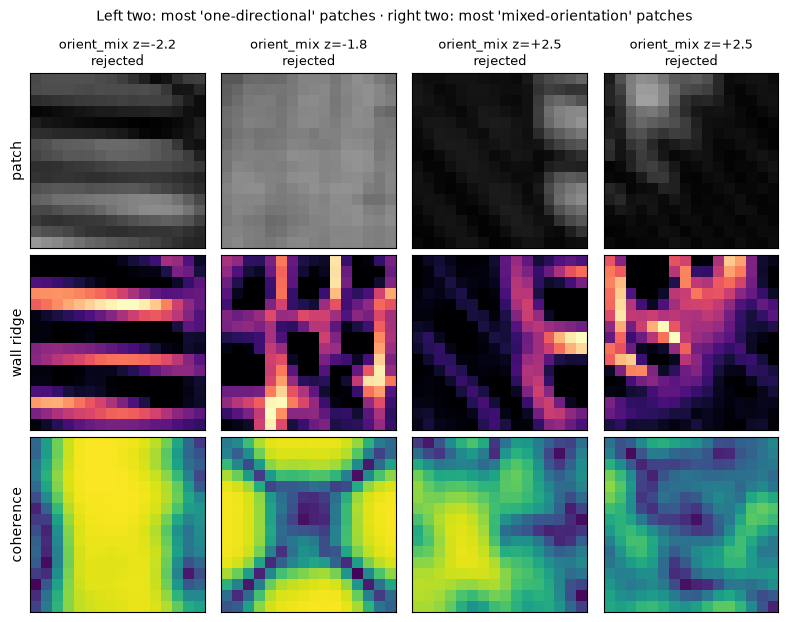

In [ ]:
examples = Z.sort_values("orient_mix")["candidate"].index[[0, 1, -2, -1]]
fig, axes = plt.subplots(3, 4, figsize=(8, 6.3))
for c, idx in enumerate(examples):
    p = as_seen_by_llm(get_patch(gpt_history.iloc[idx]))
    coh, _ = orientation_coherence_map(p)
    axes[0, c].imshow(p, cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(f"orient_mix z={Z.loc[idx,'orient_mix']:+.1f}\n{'PICKED' if Z_y[idx] else 'rejected'}", fontsize=9)
    axes[1, c].imshow(sato(p, sigmas=[1, 1.5], black_ridges=True), cmap="magma")
    axes[2, c].imshow(coh, cmap="viridis", vmin=0, vmax=1)
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("patch"); axes[1, 0].set_ylabel("wall ridge"); axes[2, 0].set_ylabel("coherence")
plt.suptitle("Left two: most 'one-directional' patches · right two: most 'mixed-orientation' patches", fontsize=10)
plt.tight_layout(); plt.show()

The maps visualize what the ridge and orientation detectors respond to. Mixed gradient
directions can arise from bends or junction-like structure, but also from noise. These descriptors
should be interpreted together with contrast and edge information, rather than as physical labels.

## Step 2 — One feature at a time

The left plot describes whether selected patches have higher or lower feature values than rejected
patches. The right plot asks how often choosing the maximum of one feature predicts the winner.
These are descriptive checks, not independent proof of a mechanism. P-values treating all candidate
patches as independent are omitted because candidates share sets and can overlap spatially.

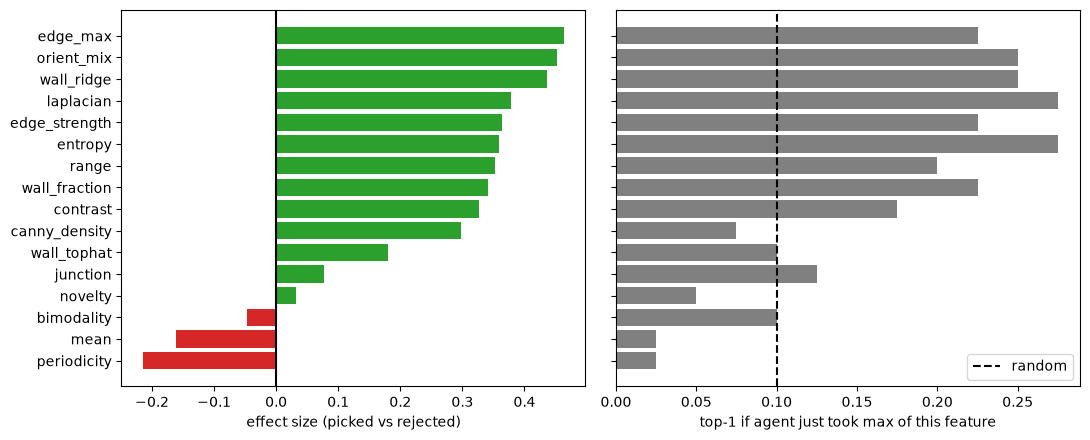

,feature,effect_size,greedy_top1,greedy_top3
0,edge_max,0.464,0.225,0.600
1,orient_mix,0.452,0.250,0.525
2,wall_ridge,0.436,0.250,0.500
3,laplacian,0.378,0.275,0.500
4,edge_strength,0.363,0.225,0.450
5,entropy,0.359,0.275,0.525
6,range,0.353,0.200,0.525
7,wall_fraction,0.341,0.225,0.500
8,contrast,0.327,0.175,0.475
9,canny_density,0.298,0.075,0.450


In [ ]:
from scipy.stats import mannwhitneyu

def rank_of_choice(scores, labels, steps):
    ranks = []
    for s in np.unique(steps):
        m = steps == s
        order = np.argsort(-scores[m], kind="stable")
        ranks.append(int(np.where(order == np.argmax(labels[m]))[0][0]) + 1)
    return np.array(ranks)

single = []
for f in MY_FEATURES:
    a, b = Z.loc[Z_y == 1, f], Z.loc[Z_y == 0, f]
    U, p = mannwhitneyu(a, b)
    r = rank_of_choice(Z[f].values, Z_y, Z_steps)
    single.append({"feature": f, "effect_size": 2*U/(len(a)*len(b)) - 1, "greedy_top1": np.mean(r == 1), "greedy_top3": np.mean(r <= 3)})
single = pd.DataFrame(single).sort_values("effect_size", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
colors = ["tab:green" if e > 0 else "tab:red" for e in single["effect_size"]]
ax[0].barh(single["feature"], single["effect_size"], color=colors); ax[0].axvline(0, color="k")
ax[0].invert_yaxis(); ax[0].set_xlabel("effect size (picked vs rejected)")
ax[1].barh(single["feature"], single["greedy_top1"], color="gray"); ax[1].axvline(0.1, color="k", ls="--", label="random")
ax[1].set_xlabel("top-1 if agent just took max of this feature"); ax[1].legend()
plt.tight_layout(); plt.show()
single.round(3)

Use the computed single-feature plot rather than the historical stand-in ranking. The
cross-validated single-feature baseline reselects its feature on training decisions within each fold.
A combination of features can predict choices even when a single maximum-feature rule fails.

## Step 3 — A model built for "choose 1 of 10"

Each candidate receives utility $u_i=w^Tz_i$. The choice probability is
$P(i)=\exp(u_i)/\sum_j\exp(u_j)$. Fitting finds weights that increase the observed winners'
probabilities, with an L2 penalty to reduce overfitting. The fitted utility is a predictive surrogate
for reward, not uniquely identified internal reasoning.

Before applying the model to GPT choices, test it on the simulated agent, where the known reward
weights are 0.10 for brightness, 0.35 for contrast, and 0.55 for edges.

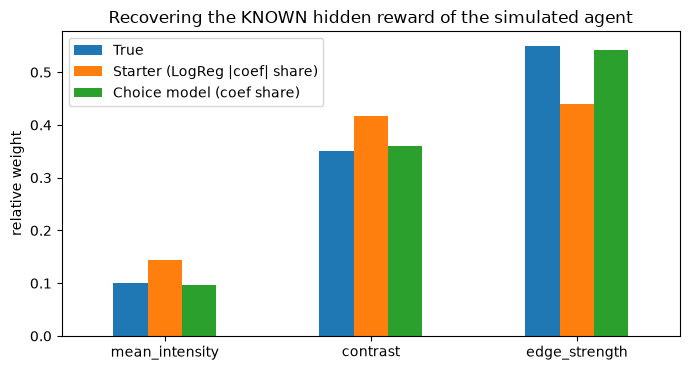

,True,Starter (LogReg |coef| share),Choice model (coef share)
mean_intensity,0.10,0.144,0.097
contrast,0.35,0.417,0.360
edge_strength,0.55,0.439,0.542


In [ ]:
from scipy.optimize import minimize

class ConditionalLogit:
    """Discrete-choice model: P(pick i | set) = softmax_i(w · x_i), fitted by penalised maximum likelihood."""
    def __init__(self, l2=1.0):
        self.l2 = l2
    def fit(self, X, y, groups):
        sets = [np.where(groups == g)[0] for g in np.unique(groups)]
        def nll(w):
            loss, grad = self.l2 * w @ w, 2 * self.l2 * w
            for ii in sets:
                u = X[ii] @ w; u -= u.max()
                p = np.exp(u); p /= p.sum()
                k = np.argmax(y[ii])
                loss -= np.log(p[k] + 1e-12)
                grad -= X[ii][k] - p @ X[ii]
            return loss, grad
        result = minimize(nll, np.zeros(X.shape[1]), jac=True, method="L-BFGS-B")
        if not result.success:
            raise RuntimeError(f"Choice-model optimization failed: {result.message}")
        self.coef_ = result.x
        return self
    def score(self, X):
        return X @ self.coef_
    def log_prob_of_choice(self, X, y, groups):
        out = []
        for g in np.unique(groups):
            ii = groups == g; u = X[ii] @ self.coef_; u -= u.max()
            out.append(u[np.argmax(y[ii])] - np.log(np.exp(u).sum()))
        return np.array(out)

# --- sanity check on the simulated agent (true weights known) ---
sim_X = history[feature_cols].values
sim = ConditionalLogit(l2=0.01).fit(sim_X, history["selected"].values, history["step"].values)
w_sim = pd.Series(sim.coef_, index=feature_cols)

check = pd.DataFrame({
    "True": pd.Series(weights),
    "Starter (LogReg |coef| share)": importance,
    "Choice model (coef share)": w_sim.clip(lower=0) / w_sim.clip(lower=0).sum(),
}).loc[feature_cols]
check.plot(kind="bar", figsize=(7, 3.8)); plt.ylabel("relative weight"); plt.xticks(rotation=0)
plt.title("Recovering the KNOWN hidden reward of the simulated agent"); plt.tight_layout(); plt.show()
check.round(3)

The simulated agent provides a sanity check on weight ordering and prediction. Since it always
chooses the maximum reward, many weight vectors can produce the same observed winners. Coefficient
shares are approximate recovery under regularization, not unique identification of the true reward.
Adding a common constant to every utility never changes a choice; softmax scale also reflects noise.

## Step 4 — Compare predictions on held-out decisions

All methods use the same leave-one-decision-out folds. Single-feature selection happens inside each
fold. The bootstrap intervals describe variation across the observed decisions; overlapping patches,
shared training folds, and adaptive feature design limit their interpretation as independent trials.

On the starter's own train/test split (10 test decisions): my model top-1 = 50%


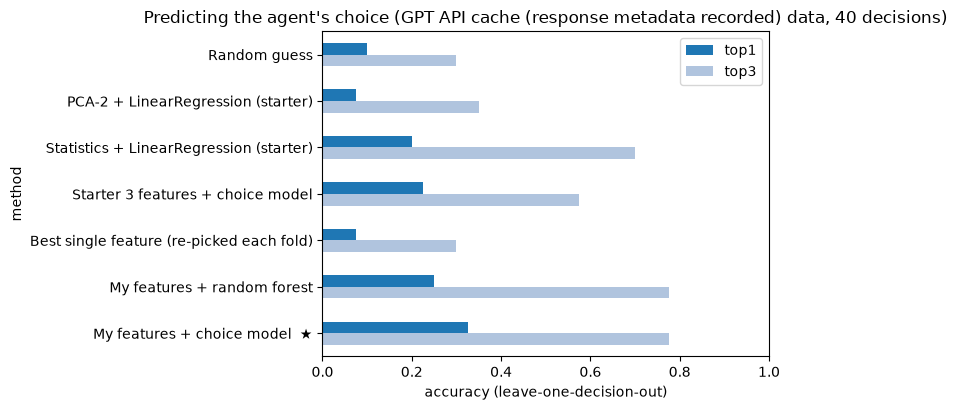

,top1,top3,mean_rank,top1_95CI
method,,,,
Random guess,0.100,0.300,5.500,—
PCA-2 + LinearRegression (starter),0.075,0.350,5.025,0%–18%
Statistics + LinearRegression (starter),0.200,0.700,3.075,8%–32%
Starter 3 features + choice model,0.225,0.575,3.425,10%–35%
Best single feature (re-picked each fold),0.075,0.300,4.725,0%–18%
My features + random forest,0.250,0.775,2.700,12%–38%
My features + choice model ★,0.325,0.775,2.725,18%–48%


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import skew, kurtosis

X_pix  = X_patches.reshape(len(X_patches), -1)
X_stat = np.array([[p.mean(), p.std(), np.ptp(p), skew(p.ravel()), kurtosis(p.ravel())] for p in X_patches])
X_my   = Z[MY_FEATURES].values
y_all, s_all = y_selected.astype(int), np.array(step_ids)
assert (s_all == Z_steps).all() and (np.array(candidate_ids) == Z["candidate"].values).all()

# starter 3 features, z-scored within each step like mine
starter3 = Z[[]].copy()
for f, fn in {"mean_intensity": np.mean, "contrast": np.std}.items():
    starter3[f] = [fn(p) for p in X_patches]
starter3["edge_strength"] = [np.mean(np.hypot(*np.gradient(p))) for p in X_patches]
starter3 = starter3.groupby(s_all).transform(lambda c: (c - c.mean()) / (c.std(ddof=0) + 1e-9)).values

def loso(fit_predict):
    scores = np.zeros(len(y_all))
    for s in np.unique(s_all):
        te = s_all == s
        scores[te] = fit_predict(~te, te)
    return rank_of_choice(scores, y_all, s_all)

methods = {
    "PCA-2 + LinearRegression (starter)":
        lambda tr, te: make_pipeline(PCA(2, svd_solver="full"), LinearRegression())
                       .fit(X_pix[tr], y_all[tr]).predict(X_pix[te]),
    "Statistics + LinearRegression (starter)":
        lambda tr, te: LinearRegression().fit(X_stat[tr], y_all[tr]).predict(X_stat[te]),
    "Starter 3 features + choice model":
        lambda tr, te: ConditionalLogit(1.0).fit(starter3[tr], y_all[tr], s_all[tr]).score(starter3[te]),
    "Best single feature (re-picked each fold)":
        lambda tr, te: X_my[te, np.argmin([rank_of_choice(X_my[tr, j], y_all[tr], s_all[tr]).mean()
                                           for j in range(X_my.shape[1])])],
    "My features + random forest":
        lambda tr, te: RandomForestClassifier(300, min_samples_leaf=5, class_weight="balanced", random_state=0)
                       .fit(X_my[tr], y_all[tr]).predict_proba(X_my[te])[:, 1],
    "My features + choice model  ★":
        lambda tr, te: ConditionalLogit(1.0).fit(X_my[tr], y_all[tr], s_all[tr]).score(X_my[te]),
}

boot_rng = np.random.default_rng(0)
summary = [{"method": "Random guess", "top1": 0.10, "top3": 0.30, "mean_rank": 5.5, "top1_95CI": "—"}]
ranks_by_method = {}
for name, fn in methods.items():
    r = loso(fn); ranks_by_method[name] = r
    bs = [np.mean(boot_rng.choice(r, len(r)) == 1) for _ in range(2000)]
    summary.append({"method": name, "top1": np.mean(r == 1), "top3": np.mean(r <= 3), "mean_rank": r.mean(),
                    "top1_95CI": f"{np.percentile(bs, 2.5):.0%}–{np.percentile(bs, 97.5):.0%}"})
summary = pd.DataFrame(summary).set_index("method")

# the starter's exact split (25 % of steps, random_state=42) for direct comparison with the cells above
final_on_split = ConditionalLogit(1.0).fit(X_my[train_mask], y_all[train_mask], s_all[train_mask])
split_acc = decision_accuracy(final_on_split.score(X_my[test_mask]), y_all[test_mask], s_all[test_mask])
print(f"On the starter's own train/test split ({len(test_steps)} test decisions): my model top-1 = {split_acc:.0%}")

ax = summary[["top1", "top3"]].plot(kind="barh", figsize=(8, 4.2), color=["tab:blue", "lightsteelblue"])
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_xlabel("accuracy (leave-one-decision-out)")
ax.set_title(f"Predicting the agent's choice ({DATA_SOURCE} data, {len(np.unique(s_all))} decisions)")
plt.tight_layout(); plt.show()
summary.round(3)

The computed table above uses the currently loaded source. Top-1 measures the exact winner;
top-3 measures whether the observed choice is among the three highest scores. Compare methods using
the same leave-one-decision-out table. The earlier 75/25 split is a separate evaluation and should
not be mixed with these numbers. Small differences between methods require more independent data.

## Step 5 — Which feature groups help prediction?

Remove one group, refit, and measure the loss of held-out log-likelihood. A positive drop means the
group adds predictive information given the remaining features. A negative value means removing it
slightly improves this validation score. Correlated features can substitute for each other; neither
sign proves the agent causally used or ignored that cue.

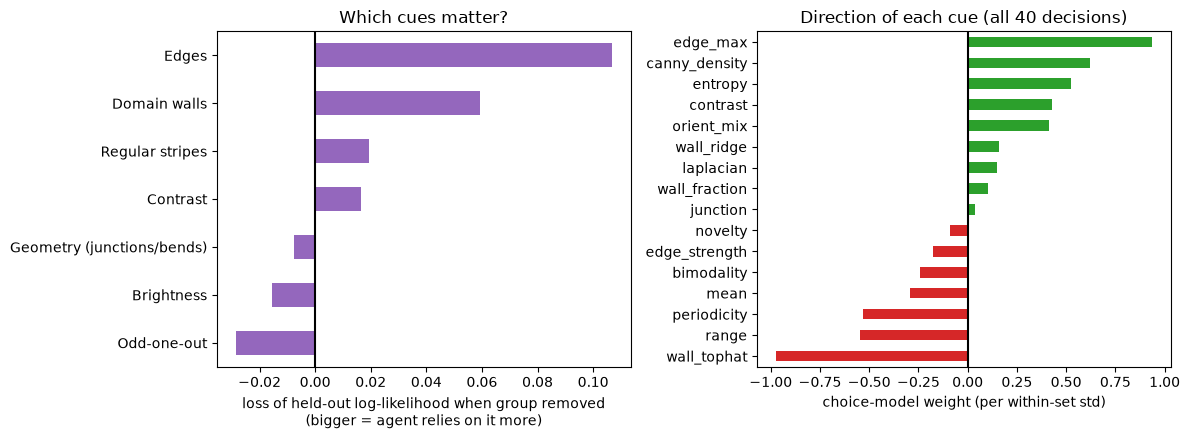

Held-out log-likelihood per decision: model -1.74 vs random -2.30


Edges                         0.107
Domain walls                  0.059
Regular stripes               0.019
Contrast                      0.016
Geometry (junctions/bends)   -0.007
Brightness                   -0.015
Odd-one-out                  -0.029
dtype: float64

In [ ]:
def loso_loglik(cols):
    X = Z[cols].values; ll = []
    for s in np.unique(s_all):
        te = s_all == s
        m = ConditionalLogit(1.0).fit(X[~te], y_all[~te], s_all[~te])
        ll.append(m.log_prob_of_choice(X[te], y_all[te], s_all[te])[0])
    return np.mean(ll)

full_ll = loso_loglik(MY_FEATURES)
ablation = pd.Series({g: full_ll - loso_loglik([f for f in MY_FEATURES if f not in cols])
                      for g, cols in GROUPS.items()}).sort_values(ascending=False)

final_model = ConditionalLogit(1.0).fit(X_my, y_all, s_all)
coefs = pd.Series(final_model.coef_, index=MY_FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ablation.plot(kind="barh", ax=ax[0], color="tab:purple"); ax[0].invert_yaxis()
ax[0].set_xlabel("loss of held-out log-likelihood when group removed\n(bigger = agent relies on it more)")
ax[0].axvline(0, color="k")
coefs.plot(kind="barh", ax=ax[1], color=["tab:red" if v < 0 else "tab:green" for v in coefs])
ax[1].set_xlabel("choice-model weight (per within-set std)"); ax[1].axvline(0, color="k")
ax[0].set_title("Which cues matter?"); ax[1].set_title("Direction of each cue (all 40 decisions)")
plt.tight_layout(); plt.show()
print(f"Held-out log-likelihood per decision: model {full_ll:.2f} vs random {np.log(0.1):.2f}")
ablation.round(3)

### Where does the model get it wrong?

I always look at the misses. If the model's pick (blue dashed) and the agent's pick (red) look equally "interesting"
to me, the miss is a near-tie and the model has basically understood the logic. If the agent picked something my features
can't describe, that points to a missing feature.

27 misses; rank of the true pick in those misses: [2, 3, 2, 2, 3, 3, 8, 4, 2, 5, 4, 4, 8, 2, 5, 2, 3, 3, 7, 2, 3, 2, 3, 2, 2, 7, 3]


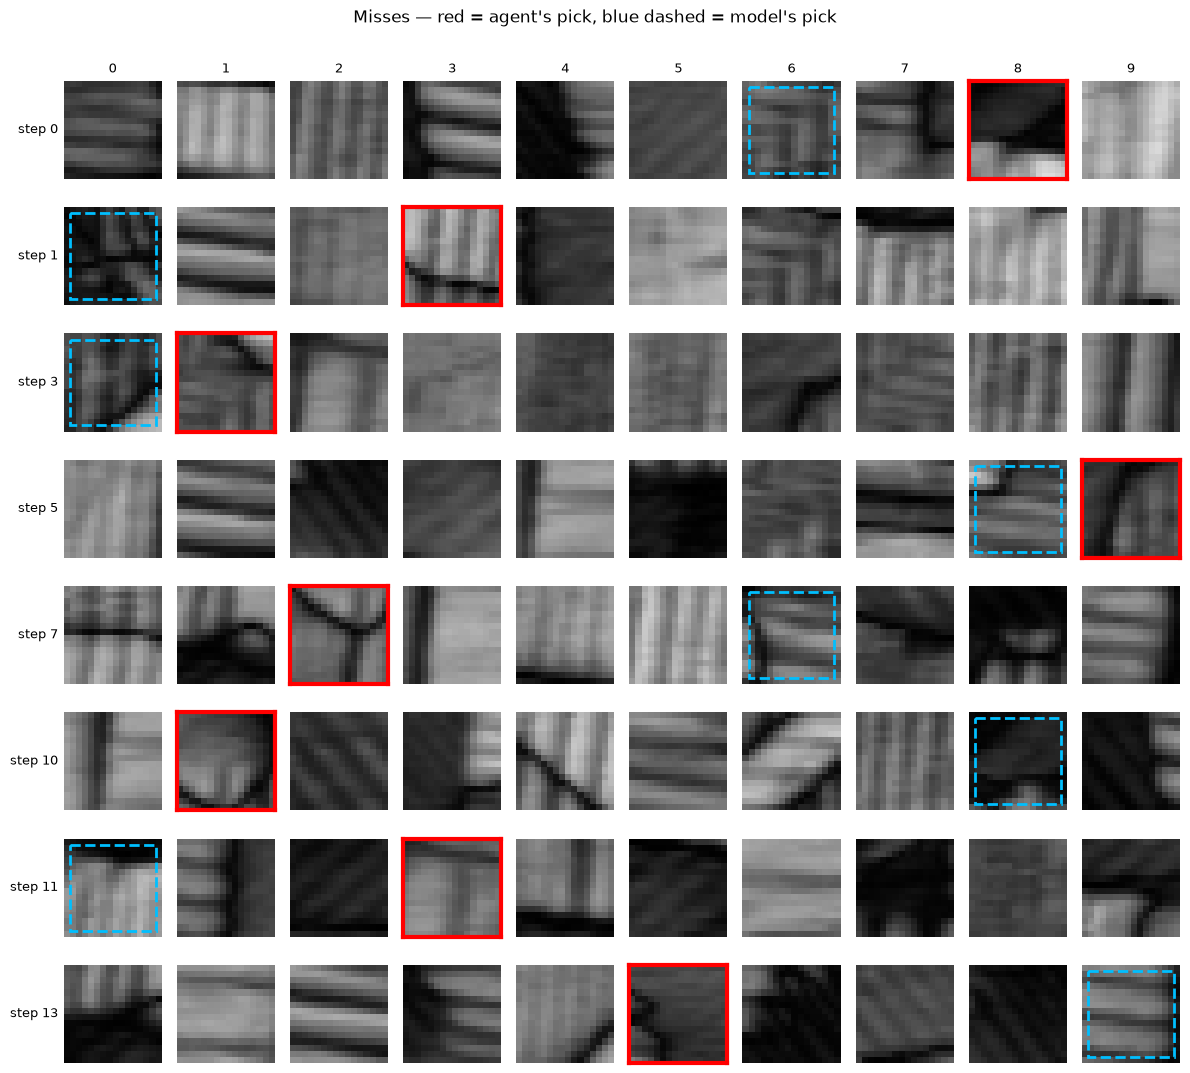

In [ ]:
loo_pick, loo_rank = {}, {}
for s in np.unique(s_all):
    te = s_all == s
    sc = ConditionalLogit(1.0).fit(X_my[~te], y_all[~te], s_all[~te]).score(X_my[te])
    loo_pick[s] = int(np.argmax(sc))
    loo_rank[s] = int(rank_of_choice(sc, y_all[te], s_all[te])[0])
misses = [s for s in loo_rank if loo_rank[s] > 1]
print(f"{len(misses)} misses; rank of the true pick in those misses: {[loo_rank[s] for s in misses]}")
show_decisions(gpt_history, misses[:8], extra=loo_pick,
               title="Misses — red = agent's pick, blue dashed = model's pick")

Read the largest positive ablation values for the current data source. In the saved GPT run,
the **Edges** group contributes the largest gain, followed by **Domain walls**, meaning the thin
dark-line descriptors. Geometry has no positive incremental gain in this particular comparison.
This differs from the earlier stand-in analysis, which favored geometry more strongly.

A true selection ranked second is a ranking near-miss. It does not establish a subjective near-tie
or random tie-breaking; those claims require repeated choices on the same images.

## Step 6 — New candidate sets on this same image

Fit on all 40 training decisions, freeze the weights, and evaluate 12 new sets from seed 2026.
Training and test labels must come from the same declared source. These sets test new candidate
combinations and coordinates on the same scan, not generalization to a new scan or material.

GPT API cache (response metadata recorded): top-1=66.7%, top-3=100.0%, mean rank=1.42


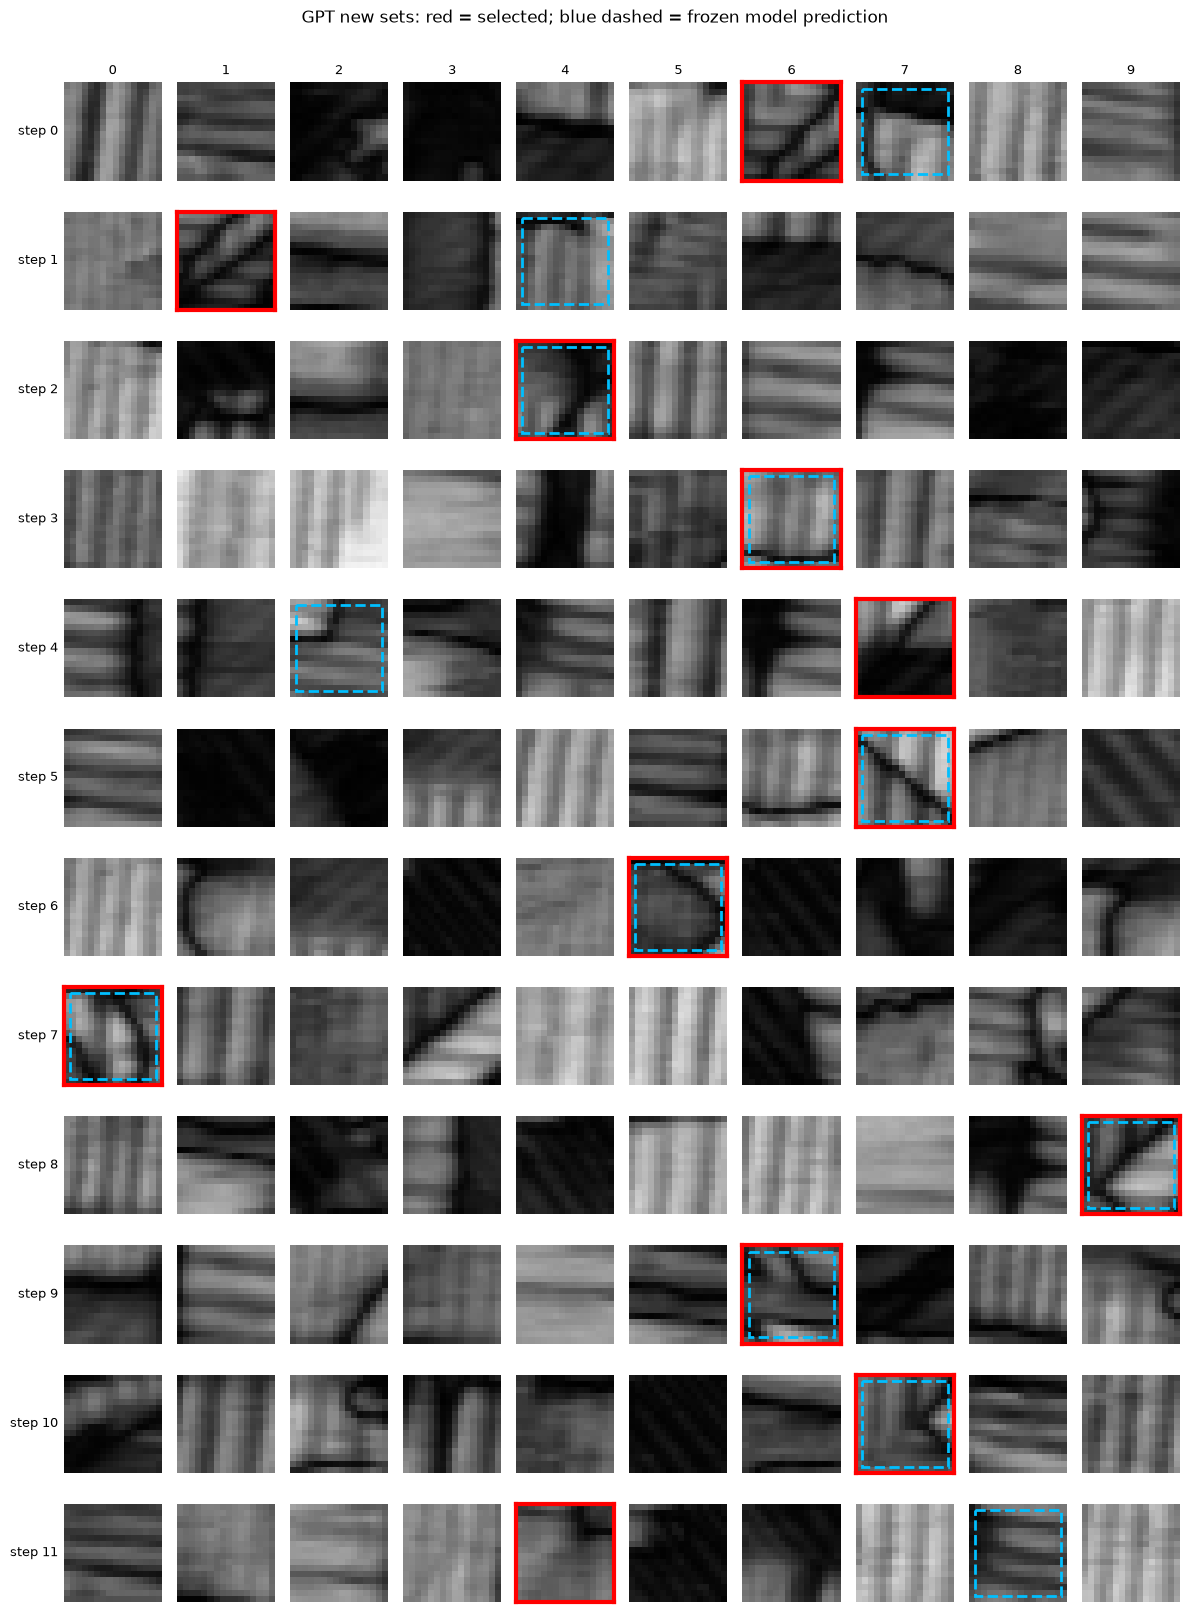

In [ ]:
N_NEW = 12
unseen = None
if SOURCE_KIND == "GPT":
    if Path("gpt_unseen.csv").exists():
        unseen, UNSEEN_SOURCE = read_cache("gpt_unseen.csv", img, MODEL, 2026, N_NEW)
    elif USE_GPT:
        unseen, UNSEEN_SOURCE = collect_history("gpt_unseen.csv", img, MODEL, 2026,
            N_NEW, get_candidates, ask_gpt_record)
    else:
        UNSEEN_SOURCE = "Not scored: GPT test decisions unavailable"
        print(UNSEEN_SOURCE)
else:
    unseen = validate_history(pd.read_csv("gpt_unseen_standin.csv"), img.shape, 2026, N_NEW)
    UNSEEN_SOURCE = "STAND-IN (supplied new-set choices)"

if unseen is not None:
    Z_new = build_table(unseen)
    new_scores = final_model.score(Z_new[MY_FEATURES].values)
    new_ranks = rank_of_choice(new_scores, Z_new.selected.values, Z_new.step.values)
    model_pick = {s: int(np.argmax(new_scores[Z_new.step.values == s])) for s in np.unique(Z_new.step)}
    print(f"{UNSEEN_SOURCE}: top-1={np.mean(new_ranks==1):.1%}, "
          f"top-3={np.mean(new_ranks<=3):.1%}, mean rank={new_ranks.mean():.2f}")
    show_decisions(unseen, sorted(unseen.step.unique()), extra=model_pick,
        title=f"{SOURCE_KIND} new sets: red = selected; blue dashed = frozen model prediction")

### (Optional, needs a key) Ask GPT to think aloud

Another way to decipher an LLM is simply to **ask it why**. The cell below repeats a few decisions but asks for a
one-sentence reason as well. I then check whether its stated reasons match what the model learned. LLM explanations
aren't always faithful to what actually drove the choice, so I treat them as a hypothesis to test against the choice
model, not as ground truth.

In [ ]:
if USE_GPT and RUN_REASON_API_CALLS:
    import re
    def ask_gpt_with_reason(patches):
        content = [{"type": "input_text", "text":
            "You are controlling an autonomous microscopy experiment. Choose the ONE candidate that is the most "
            "scientifically informative location to measure next. Use only the visual information. "
            "Answer as: <integer 0-9> | <one short sentence explaining why>"}]
        for i, im in enumerate(patch_to_base64(p) for p in patches):
            content += [{"type": "input_text", "text": f"Candidate {i}"},
                        {"type": "input_image", "image_url": im, "detail": "high"}]
        r = client.responses.create(model=MODEL, input=[{"role": "user", "content": content}],
                                    extra_headers={"Accept-Encoding": "identity"})
        return r.output_text
    reasons = []
    for s in range(5):
        sd = gpt_history[gpt_history["step"] == s].sort_values("candidate")
        reasons.append(ask_gpt_with_reason([get_patch(r) for _, r in sd.iterrows()]))
        print(f"step {s}: {reasons[-1]}")
    words = pd.Series(re.findall(r"[a-z]+", " ".join(reasons).lower())).value_counts()
    print(words[words.index.isin(["wall", "walls", "boundary", "boundaries", "domain", "domains", "junction",
                                  "edge", "edges", "contrast", "stripes", "texture", "defect", "interface"])])
else:
    print("Reason API calls disabled. Set RUN_REASON_API_CALLS=True to opt in.")

Reason API calls disabled. Set RUN_REASON_API_CALLS=True to opt in.


## My answer

I represent each patch using brightness, contrast, edges, thin dark ridges, orientation mixture,
junction-like structure, periodicity, and difference from other patches. I standardize each feature
within its candidate set, then fit a conditional-logit model:

$$u_{si}=w^Tz_{si},\qquad P(i\mid s)=\frac{\exp(u_{si})}{\sum_{j=0}^{9}\exp(u_{sj})}.$$

The fitted reward is the linear utility, and the predicted choice is its maximum in each set.
Training minimizes the negative log probability of the observed selections plus an L2 penalty.
An intercept cancels within each set, so none is needed. The weights describe a predictive preference
model, subject to the feature definitions, noise assumption, correlations, and regularization.

The next cell computes the answer, confidence intervals, coefficients, and predictions from the
current run and identifies the data source. The saved results now describe **actual GPT API
choices**, with the earlier stand-in data kept separately. Performance on new coordinates from
this image does not establish generalization to another scan.

In [ ]:

from IPython.display import display, Markdown
import json
from scipy.stats import binomtest
from importlib.metadata import version

out_dir = Path("verified_results")
out_dir.mkdir(exist_ok=True)
summary.to_csv(out_dir / "method_comparison.csv")
coefs.rename("coefficient").to_csv(out_dir / "choice_model_weights.csv")
ablation.rename("heldout_loglik_drop").to_csv(out_dir / "feature_group_ablation.csv")
predictions = pd.DataFrame({"step": sorted(loo_rank), "predicted_candidate": [loo_pick[s] for s in sorted(loo_rank)],
    "selected_candidate": gpt_history[gpt_history.selected==1].sort_values("step").candidate.values,
    "selected_rank": [loo_rank[s] for s in sorted(loo_rank)]})
predictions.to_csv(out_dir / "leave_one_decision_out_predictions.csv", index=False)
if unseen is not None:
    pd.DataFrame({"step": sorted(model_pick), "predicted_candidate": [model_pick[s] for s in sorted(model_pick)],
        "selected_candidate": unseen[unseen.selected==1].sort_values("step").candidate.values,
        "selected_rank": new_ranks}).to_csv(out_dir / "new_set_predictions.csv", index=False)

choice_key = next(k for k in ranks_by_method if "choice model" in k and k.startswith("My features"))
rf_key = "My features + random forest"
cr, rr = ranks_by_method[choice_key], ranks_by_method[rf_key]
rf_only, choice_only = int(((rr==1)&(cr!=1)).sum()), int(((cr==1)&(rr!=1)).sum())
discordant = rf_only + choice_only
paired_p = binomtest(rf_only, discordant, .5).pvalue if discordant else 1.0
lo, hi = wilson_interval(int((cr==1).sum()), len(cr))
text = f"# Day 20 verified explanation and results\n\nSource: **{DATA_SOURCE}**.\n\n"
text += "The task is to predict which of ten patches a chooser selects and fit a reward model that explains those choices. "
text += "The reward is a weighted sum of image features, scaled relative to the other nine candidates in each decision. "
text += "A softmax converts rewards to selection probabilities; fitting increases the probability of the observed selections.\n\n"
text += "| Method | Exact pick | Top 3 | Mean rank |\n|---|---:|---:|---:|\n"
for name, row in summary.iterrows():
    text += f"| {name} | {row.top1:.1%} | {row.top3:.1%} | {row.mean_rank:.3f} |\n"
text += f"\nChoice model: {(cr==1).sum()}/{len(cr)} exact; descriptive Wilson 95% interval {lo:.1%}–{hi:.1%}. "
text += "The interval assumes independent decisions; spatial overlap and adaptive feature design limit that assumption.\n\n"
if unseen is not None:
    nlo, nhi = wilson_interval(int((new_ranks==1).sum()), len(new_ranks))
    text += f"New sets ({UNSEEN_SOURCE}): {(new_ranks==1).sum()}/{len(new_ranks)} exact "
    text += f"({np.mean(new_ranks==1):.1%}), {(new_ranks<=3).sum()}/{len(new_ranks)} top-3 "
    text += f"({np.mean(new_ranks<=3):.1%}); exact-pick Wilson interval {nlo:.1%}–{nhi:.1%}.\n\n"
text += f"RF-only correct decisions: {rf_only}; choice-model-only correct: {choice_only}; "
text += f"two-sided paired exact test p={paired_p:.3f}. This is exploratory, not a claim that the methods are equivalent.\n\n"
text += "Largest group-ablation loss: **" + ablation.index[0] + "**. "
text += f"The chosen patch ranked second in {sum(loo_rank[s]==2 for s in misses)} of {len(misses)} misses. "
text += "The ablation identifies incremental predictive information in the named group; it does not prove the chooser's causal reasoning.\n\n"
text += "Only 40 choices were observed, even though the training table has 400 rows. Each set contributes one selection. "
text += "Feature design was informed by this image and earlier stand-in choices; comparisons remain exploratory. New sets share the same image and can overlap training patches. "
text += "Amplitude alone cannot confirm polarization direction or identify every dark line as a domain wall.\n\n"
if SOURCE_KIND == "GPT":
    text += "This run analyzes GPT-labelled decisions. API metadata records are retained when available; "
    text += "the model describes observed GPT preferences, not a uniquely identified internal reward or scientific optimality.\n\n"
else:
    text += "This run uses stand-in choices and does not establish GPT preferences. "
    text += "The original notebook attributes the stand-in to Claude, but the stand-in CSVs do not prove origin or timing.\n\n"
text += "To run on GPT: set OPENAI_API_KEY locally and rerun this notebook; keep gpt-5.6-sol as the requested model. "
text += "The collector saves resumable progress and provenance metadata, and never substitutes stand-in labels for GPT test labels. "
text += "An existing GPT CSV without provenance is labelled as an unverified supplied cache.\n"
(out_dir / "explanation_and_results.md").write_text(text, encoding="utf-8")
(out_dir / "run_metadata.json").write_text(json.dumps({"source": DATA_SOURCE, "source_kind": SOURCE_KIND,
    "unseen_source": UNSEEN_SOURCE, "n_decisions": int(gpt_history.step.nunique()),
    "features": MY_FEATURES, "l2": 1.0, "seeds": {"history":123,"new_sets":2026},
    "packages": {p: version(p) for p in ["numpy","pandas","scipy","scikit-learn","scikit-image","igor2","openai"]}}, indent=2), encoding="utf-8")
display(Markdown(text))


# Day 20 verified explanation and results

Source: **GPT API cache (response metadata recorded)**.

The task is to predict which of ten patches a chooser selects and fit a reward model that explains those choices. The reward is a weighted sum of image features, scaled relative to the other nine candidates in each decision. A softmax converts rewards to selection probabilities; fitting increases the probability of the observed selections.

| Method | Exact pick | Top 3 | Mean rank |
|---|---:|---:|---:|
| Random guess | 10.0% | 30.0% | 5.500 |
| PCA-2 + LinearRegression (starter) | 7.5% | 35.0% | 5.025 |
| Statistics + LinearRegression (starter) | 20.0% | 70.0% | 3.075 |
| Starter 3 features + choice model | 22.5% | 57.5% | 3.425 |
| Best single feature (re-picked each fold) | 7.5% | 30.0% | 4.725 |
| My features + random forest | 25.0% | 77.5% | 2.700 |
| My features + choice model  ★ | 32.5% | 77.5% | 2.725 |

Choice model: 13/40 exact; descriptive Wilson 95% interval 20.1%–48.0%. The interval assumes independent decisions; spatial overlap and adaptive feature design limit that assumption.

New sets (GPT API cache (response metadata recorded)): 8/12 exact (66.7%), 12/12 top-3 (100.0%); exact-pick Wilson interval 39.1%–86.2%.

RF-only correct decisions: 2; choice-model-only correct: 5; two-sided paired exact test p=0.453. This is exploratory, not a claim that the methods are equivalent.

Largest group-ablation loss: **Edges**. The chosen patch ranked second in 10 of 27 misses. The ablation identifies incremental predictive information in the named group; it does not prove the chooser's causal reasoning.

Only 40 choices were observed, even though the training table has 400 rows. Each set contributes one selection. Feature design was informed by this image and earlier stand-in choices; comparisons remain exploratory. New sets share the same image and can overlap training patches. Amplitude alone cannot confirm polarization direction or identify every dark line as a domain wall.

This run analyzes GPT-labelled decisions. API metadata records are retained when available; the model describes observed GPT preferences, not a uniquely identified internal reward or scientific optimality.

To run on GPT: set OPENAI_API_KEY locally and rerun this notebook; keep gpt-5.6-sol as the requested model. The collector saves resumable progress and provenance metadata, and never substitutes stand-in labels for GPT test labels. An existing GPT CSV without provenance is labelled as an unverified supplied cache.
